In [1]:
pip install xgboost plotly optuna anywidget

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import xgboost as xgb
from xgboost import XGBClassifier

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
    cross_val_score,
    GridSearchCV
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import inspect
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Citim datasetul curățat din fișierul CSV
df_clean = pd.read_csv("data/AmesHousing_cleaned.csv")

# Copie pentru analiza din acest notebook
df = df_clean.copy()

print("Dimensiuni dataset:", df.shape)
print("\nPrimele 5 rânduri:")
display(df.head())

print("\nColoane disponibile:")
print(df.columns.tolist())

print("\nValori lipsă totale:", df.isna().sum().sum())

Dimensiuni dataset: (2925, 82)

Primele 5 rânduri:


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Alley,Lot Shape,Land Contour,Lot Config,...,SalePrice,Has Basement,Has Garage,House Age at Sale,Years Since Remodel,Total SF,Total Baths,Total Porch SF,Qual x Area,Is Remodeled
0,1,526301100,20,RL,141.0,31770,NaN,IR1,Lvl,Corner,...,215000,1,1,50,50,2736.0,2.0,272,9936,0
1,2,526350040,20,RH,80.0,11622,NaN,Reg,Lvl,Inside,...,105000,1,1,49,49,1778.0,1.0,260,4480,0
2,3,526351010,20,RL,81.0,14267,NaN,IR1,Lvl,Corner,...,172000,1,1,52,52,2658.0,1.5,429,7974,0
3,4,526353030,20,RL,93.0,11160,NaN,Reg,Lvl,Corner,...,244000,1,1,42,42,4220.0,3.5,0,14770,0
4,5,527105010,60,RL,74.0,13830,NaN,IR1,Lvl,Inside,...,189900,1,1,13,12,2557.0,2.5,246,8145,1



Coloane disponibile:
['Order', 'PID', 'MS SubClass', 'MS Zoning', 'Lot Frontage', 'Lot Area', 'Alley', 'Lot Shape', 'Land Contour', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1', 'Bldg Type', 'House Style', 'Overall Qual', 'Overall Cond', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Mas Vnr Area', 'Exter Qual', 'Exter Cond', 'Foundation', 'Bsmt Qual', 'Bsmt Cond', 'Bsmt Exposure', 'BsmtFin Type 1', 'BsmtFin SF 1', 'BsmtFin Type 2', 'BsmtFin SF 2', 'Bsmt Unf SF', 'Total Bsmt SF', 'Heating', 'Heating QC', 'Central Air', 'Electrical', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF', 'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath', 'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'Kitchen Qual', 'TotRms AbvGrd', 'Functional', 'Fireplaces', 'Fireplace Qu', 'Garage Type', 'Garage Finish', 'Garage Area', 'Garage Qual', 'Garage Cond', 'Paved Drive', 'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch', 'Screen Porch', 'Fence', '

Distribuția claselor:


,Număr de case
SalePriceClass,
<100k,237
100k-130k,509
130k-180k,1036
180k-250k,684
250k-400k,397
>=400k,62


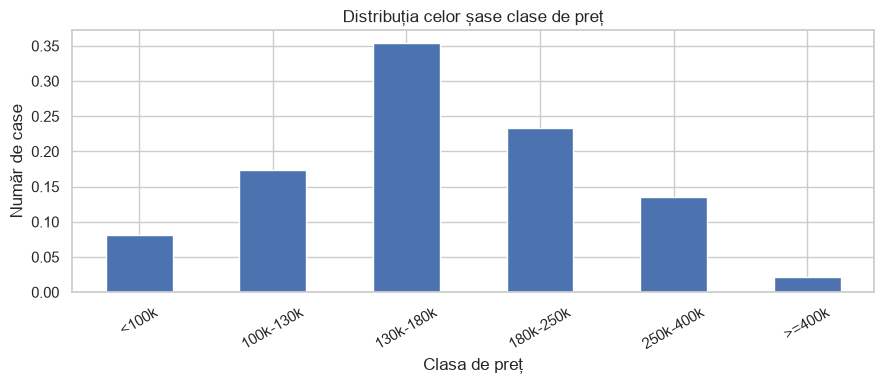

In [4]:
bins = [
    -np.inf,
    100000,
    130000,
    180000,
    250000,
    400000,
    np.inf
]

class_names = [
    "<100k",
    "100k-130k",
    "130k-180k",
    "180k-250k",
    "250k-400k",
    ">=400k"
]

# Eliminăm doar rândurile fără o țintă validă
df = df.dropna(subset=["SalePrice"]).copy()
df = df[df["SalePrice"] > 0].copy()

df["SalePriceClass"] = pd.cut(
    df["SalePrice"],
    bins=bins,
    labels=class_names,
    right=False
)

# Coduri numerice 0-5 pentru XGBoost
df["SalePriceClass"] = (
    df["SalePriceClass"].cat.codes
)

print("Distribuția claselor:")
display(
    df["SalePriceClass"]
      .value_counts()
      .sort_index()
      .rename(index=dict(enumerate(class_names)))
      .to_frame("Număr de case")
)

df["SalePriceClass"].value_counts(normalize=True).sort_index().plot(
    kind="bar", figsize=(9, 4)
)
plt.title("Distribuția celor șase clase de preț")
plt.xlabel("Clasa de preț")
plt.ylabel("Număr de case")
plt.xticks(
    ticks=range(6),
    labels=class_names,
    rotation=30
)
plt.tight_layout()
plt.show()

In [5]:
# Identificatorii nu vor fi folosiți ca predictori
id_columns = [
    col for col in ["PID", "Order"]
    if col in df.columns
]

X = df.drop(
    columns=["SalePrice", "SalePriceClass"] + id_columns
)

y = df["SalePriceClass"].astype(int)

# Identificăm automat coloanele numerice și categorice
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Număr de caracteristici numerice:", len(numeric_features))
print("Număr de caracteristici categorice:", len(categorical_features))
print("Clase existente:", sorted(y.unique()))

Număr de caracteristici numerice: 49
Număr de caracteristici categorice: 30
Clase existente: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


C:\Users\claud\AppData\Local\Temp\ipykernel_12900\397835760.py:18: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [6]:
# Compatibilitate cu versiuni diferite de scikit-learn
ohe_params = {"handle_unknown": "ignore"}

if "sparse_output" in inspect.signature(OneHotEncoder).parameters:
    ohe_params["sparse_output"] = True
else:
    ohe_params["sparse"] = True

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant",
                              fill_value="Missing")),
    ("onehot", OneHotEncoder(**ohe_params))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

In [7]:
#split
#Separăm setul de test final
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Set dezvoltare:", X_dev.shape)
print("Set test final:", X_test.shape)

Set dezvoltare: (2340, 79)
Set test final: (585, 79)


In [8]:
#Comparăm cele patru strategii de split
split_results = []

for test_size in [0.10, 0.20]:
    for stratified in [False, True]:

        X_train, X_valid, y_train, y_valid = train_test_split(
            X_dev,
            y_dev,
            test_size=test_size,
            random_state=RANDOM_STATE,
            stratify=y_dev if stratified else None
        )

        model = Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("model", XGBClassifier(
                objective="multi:softprob",
                num_class=6,
                eval_metric="mlogloss",
                n_estimators=200,
                max_depth=4,
                learning_rate=0.1,
                subsample=0.8,
                colsample_bytree=0.8,
                tree_method="hist",
                random_state=RANDOM_STATE,
                n_jobs=1
            ))
        ])

        model.fit(X_train, y_train)
        predictions = model.predict(X_valid)

        split_results.append({
            "Test size": test_size,
            "Stratified": stratified,
            "Accuracy": accuracy_score(y_valid, predictions),
            "Macro-F1": f1_score(
                y_valid, predictions,
                average="macro",
                zero_division=0
            )
        })

split_results = pd.DataFrame(split_results)
display(split_results.round(4))

,Test size,Stratified,Accuracy,Macro-F1
0,0.1,False,0.7479,0.7160
1,0.1,True,0.7393,0.7429
2,0.2,False,0.7308,0.6640
3,0.2,True,0.7415,0.7255


In [9]:
#validare k-fold: k=5 si k=10
baseline_params = {
    "objective": "multi:softprob",
    "num_class": 6,
    "eval_metric": "mlogloss",
    "n_estimators": 200,
    "max_depth": 4,
    "learning_rate": 0.1,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "tree_method": "hist",
    "random_state": RANDOM_STATE,
    "n_jobs": 1
}

cv_results = []

for k in [5, 10]:
    cv = StratifiedKFold(
        n_splits=k,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(**baseline_params))
    ])

    scores = cross_validate(
        pipeline,
        X_dev,
        y_dev,
        cv=cv,
        scoring={
            "macro_f1": "f1_macro",
            "accuracy": "accuracy"
        },
        return_train_score=True,
        n_jobs=-1
    )

    cv_results.append({
        "K": k,
        "Train Macro-F1 mean": scores["train_macro_f1"].mean(),
        "Validation Macro-F1 mean": scores["test_macro_f1"].mean(),
        "Validation Macro-F1 std": scores["test_macro_f1"].std(),
        "Validation Accuracy mean": scores["test_accuracy"].mean()
    })

cv_results = pd.DataFrame(cv_results)
display(cv_results.round(4))

,K,Train Macro-F1 mean,Validation Macro-F1 mean,Validation Macro-F1 std,Validation Accuracy mean
0,5,0.9990,0.7548,0.0176,0.7560
1,10,0.9982,0.7389,0.0352,0.7568


In [10]:
#Antrenarea modelului XGBoost de baza
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(**baseline_params))
])

baseline_pipeline.fit(X_dev, y_dev)

baseline_predictions = baseline_pipeline.predict(X_test)

print("Baseline Accuracy:",
      round(accuracy_score(y_test, baseline_predictions), 4))

print("Baseline Macro-F1:",
      round(f1_score(
          y_test, baseline_predictions,
          average="macro",
          zero_division=0
      ), 4))

Baseline Accuracy: 0.7709
Baseline Macro-F1: 0.7417


In [13]:
#Reglarea manuala a parametrilor
manual_configs = [
    {"max_depth": 3, "learning_rate": 0.10, "subsample": 0.8},
    {"max_depth": 6, "learning_rate": 0.10, "subsample": 0.8},
    {"max_depth": 7, "learning_rate": 0.10, "subsample": 0.8},
    {"max_depth": 3, "learning_rate": 0.03, "subsample": 0.7},
    {"max_depth": 4, "learning_rate": 0.20, "subsample": 0.8},
    {"max_depth": 4, "learning_rate": 0.10, "subsample": 0.6},
    {"max_depth": 2, "learning_rate": 0.10, "subsample": 0.8}
]

manual_results = []

manual_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

for config in manual_configs:

    params = baseline_params.copy()
    params.update(config)

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", XGBClassifier(**params))
    ])

    scores = cross_val_score(
        pipeline,
        X_dev,
        y_dev,
        cv=manual_cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    manual_results.append({
        **config,
        "Mean CV Macro-F1": scores.mean(),
        "Std CV Macro-F1": scores.std()
    })

manual_results = pd.DataFrame(manual_results)
manual_results = manual_results.sort_values(
    "Mean CV Macro-F1",
    ascending=False
)

display(manual_results.round(4))

,max_depth,learning_rate,subsample,Mean CV Macro-F1,Std CV Macro-F1
1,6,0.10,0.8,0.7446,0.0139
2,7,0.10,0.8,0.7412,0.0122
4,4,0.20,0.8,0.7411,0.0172
5,4,0.10,0.6,0.7408,0.0055
6,2,0.10,0.8,0.7325,0.0056
0,3,0.10,0.8,0.7297,0.0188
3,3,0.03,0.7,0.7262,0.0097


In [11]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight

#alegem configuratia optima
grid_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", XGBClassifier(
        objective="multi:softprob",
        num_class=6,
        eval_metric="mlogloss",
        tree_method="hist",
        random_state=RANDOM_STATE,
        n_jobs=1
    ))
])

param_grid = {
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.6, 0.8],
    "model__colsample_bytree": [0.5, 0.8],
    "model__min_child_weight": [1, 5, 10],
    "model__reg_lambda": [1, 5, 10],
    "model__n_estimators": [200, 400]
}

tuning_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = RandomizedSearchCV(
    estimator=grid_pipeline,
    param_distributions=param_grid,
    n_iter=60,
    scoring="f1_macro",
    cv=tuning_cv,
    n_jobs=-1,
    refit=True,
    random_state=RANDOM_STATE,
    verbose=1,
    return_train_score=True
)

sw = compute_sample_weight("balanced", y_dev)
grid_search.fit(X_dev, y_dev, model__sample_weight=sw)

print("Cei mai buni parametri:")
print(grid_search.best_params_)

print("Cel mai bun CV Macro-F1:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 60 candidates, totalling 300 fits
Cei mai buni parametri:
{'model__subsample': 0.6, 'model__reg_lambda': 5, 'model__n_estimators': 400, 'model__min_child_weight': 5, 'model__max_depth': 6, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.8}
Cel mai bun CV Macro-F1:
0.756


In [13]:
#inspectam primele configuratii
grid_results = pd.DataFrame(grid_search.cv_results_)

grid_results = grid_results.sort_values(
    "mean_test_score",
    ascending=False
)

display(
    grid_results[[
        "params",
        "mean_train_score",
        "mean_test_score",
        "std_test_score",
        "rank_test_score"
    ]].head(10).round(4)
)

,params,mean_train_score,mean_test_score,std_test_score,rank_test_score
58,"{'model__subsample': 0.6, 'model__reg_lambda':...",0.9849,0.7560,0.0193,1
33,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9951,0.7554,0.0238,2
21,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9940,0.7546,0.0206,3
30,"{'model__subsample': 0.6, 'model__reg_lambda':...",0.9801,0.7521,0.0202,4
37,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9754,0.7516,0.0237,5
39,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9622,0.7514,0.0181,6
29,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9989,0.7513,0.0156,7
49,"{'model__subsample': 0.6, 'model__reg_lambda':...",0.9974,0.7506,0.0226,8
5,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9829,0.7485,0.0210,9
12,"{'model__subsample': 0.8, 'model__reg_lambda':...",0.9842,0.7483,0.0240,10


In [14]:
#Evaluarea finală pe test
best_model = grid_search.best_estimator_
best_predictions = best_model.predict(X_test)

print("=== REZULTAT FINAL ===")
print("Best CV Macro-F1:",
      round(grid_search.best_score_, 4))

print("Test Accuracy:",
      round(accuracy_score(y_test, best_predictions), 4))

print("Test Macro-F1:",
      round(f1_score(
          y_test, best_predictions,
          average="macro",
          zero_division=0
      ), 4))

print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=list(range(6)),
    target_names=class_names,
    zero_division=0
))

=== REZULTAT FINAL ===
Best CV Macro-F1: 0.756
Test Accuracy: 0.7846
Test Macro-F1: 0.7942

Classification report:
              precision    recall  f1-score   support

       <100k       0.74      0.77      0.76        48
   100k-130k       0.69      0.76      0.73       102
   130k-180k       0.82      0.79      0.80       207
   180k-250k       0.80      0.75      0.78       137
   250k-400k       0.81      0.86      0.83        79
      >=400k       0.91      0.83      0.87        12

    accuracy                           0.78       585
   macro avg       0.80      0.79      0.79       585
weighted avg       0.79      0.78      0.79       585



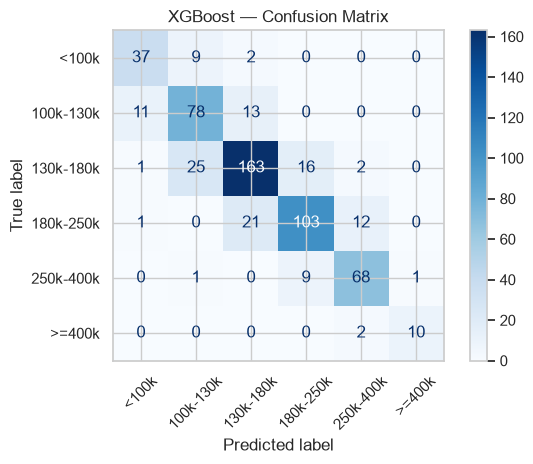

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=list(range(6)),
    display_labels=class_names,
    xticks_rotation=45,
    cmap="Blues"
)

plt.title("XGBoost — Confusion Matrix")
plt.tight_layout()
plt.show()

In [16]:
#Desenarea primului arbore și a unui arbore din modelul optimizat

# Preluăm modelul și numele caracteristicilor după encoding
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_xgb = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

print("Număr de caracteristici după encoding:", len(feature_names))
print("Număr de clase:", fitted_xgb.n_classes_)
print("Număr de estimatori:", fitted_xgb.n_estimators)

Număr de caracteristici după encoding: 255
Număr de clase: 6
Număr de estimatori: 400


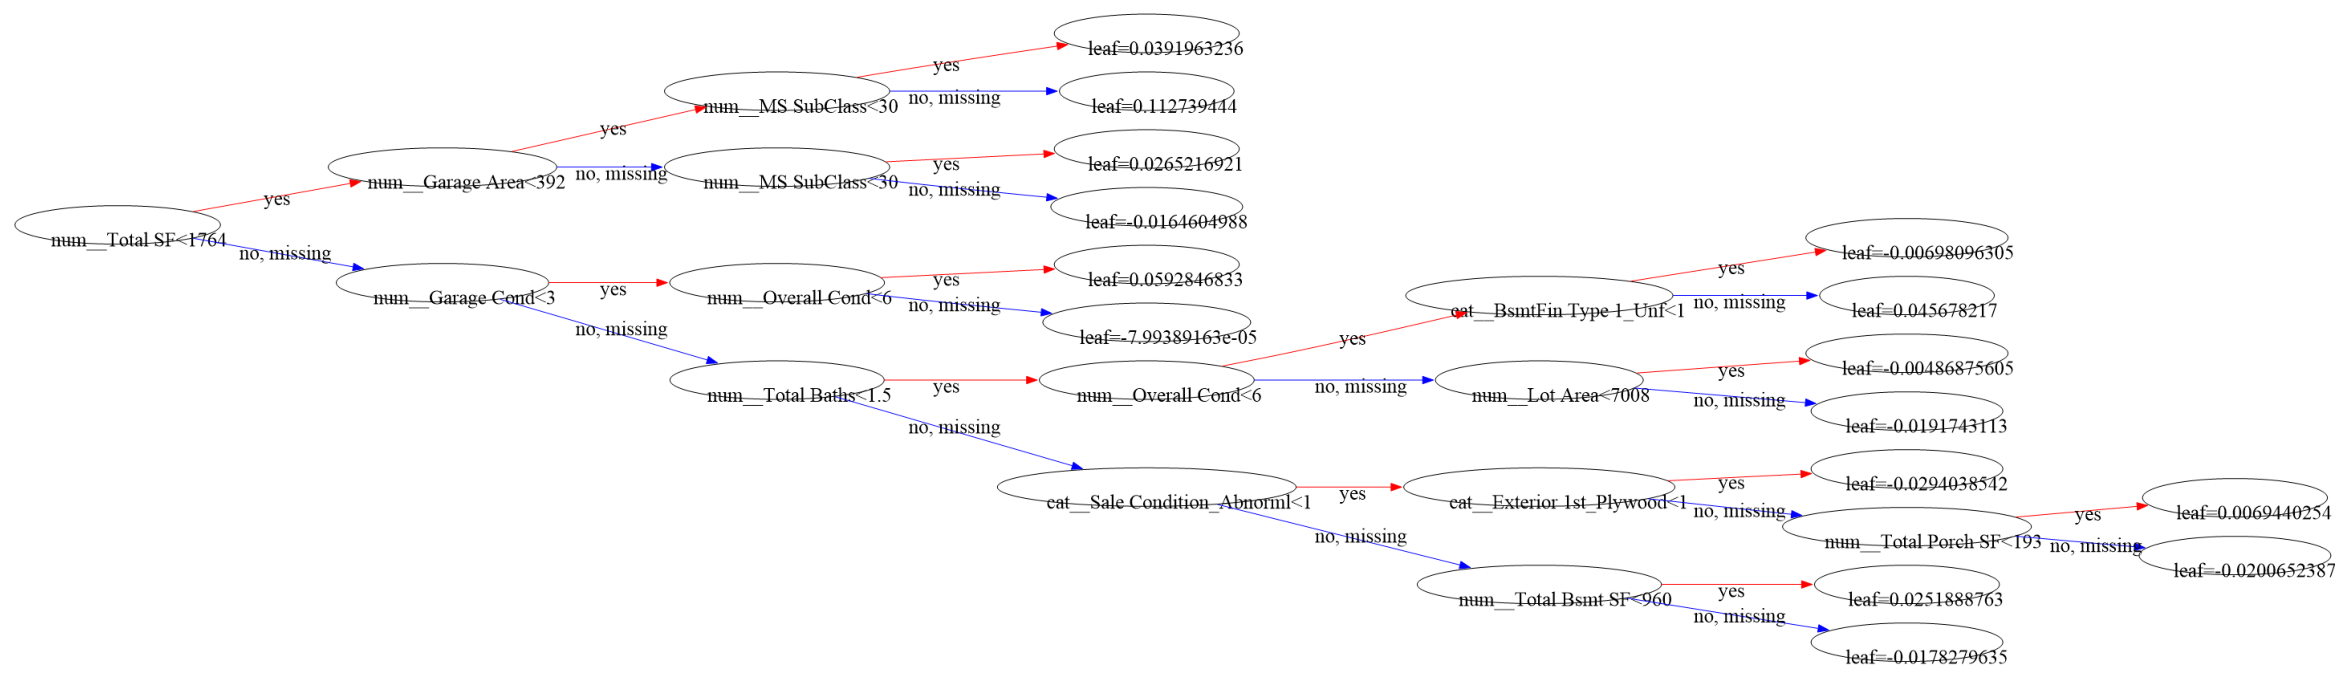

In [17]:
import matplotlib.pyplot as plt
import xgboost as xgb

booster = fitted_xgb.get_booster()

# Setăm numele caracteristicilor în booster
booster.feature_names = list(feature_names)

fig, ax = plt.subplots(figsize=(30, 16))

xgb.plot_tree(
    booster,
    tree_idx=0,
    rankdir="LR",
    ax=ax
)

plt.show()

In [14]:
%pip install graphviz

Note: you may need to restart the kernel to use updated packages.


Runda optimă: 271 din 1000
mlogloss validare la runda optimă: 0.5959


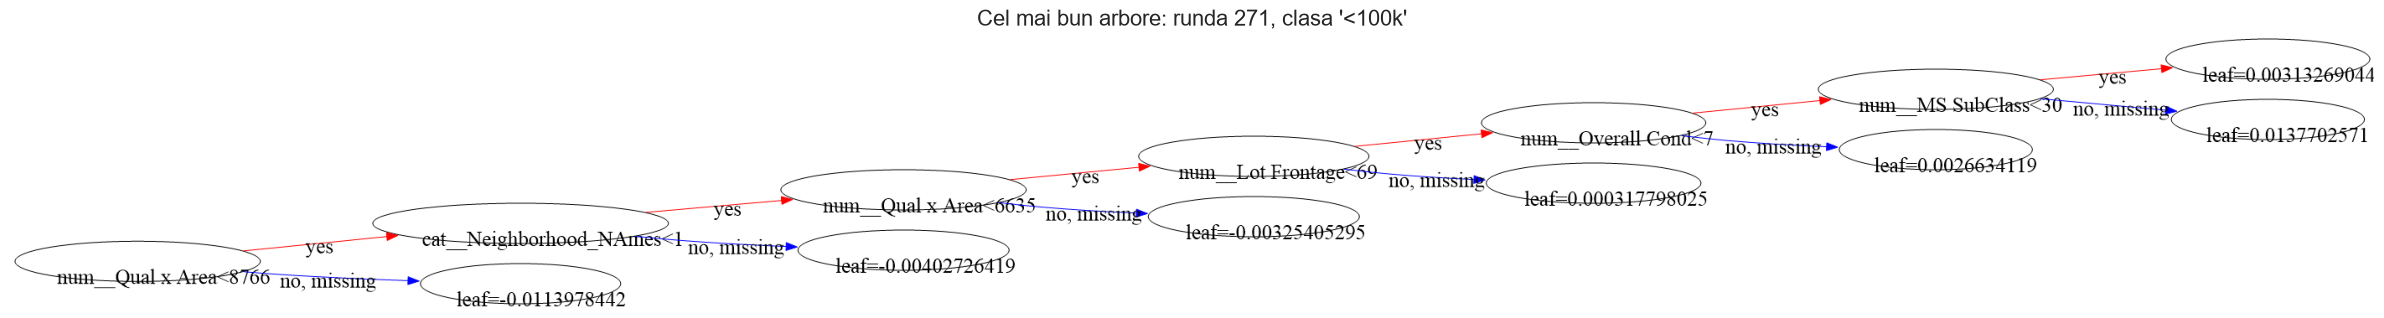

In [18]:
#Arbore din runda optima
#Pentru șase clase, fiecare rundă conține câte un arbore pentru fiecare clasă. Folosim indicele corespunzător clasei 0 din ultima rundă
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_sample_weight

# 1. Parametrii celui mai bun model din căutare (fără prefixul "model__")
best_params = {k.replace("model__", ""): v
               for k, v in grid_search.best_params_.items()}

# 2. Split intern în dev: train / validare (doar pentru găsirea rundei optime)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_dev
)

# 3. Preprocesorul se ajustează doar pe train (fără data leakage)
prep_es = clone(preprocessor).fit(X_tr)
X_tr_t = prep_es.transform(X_tr)
X_val_t = prep_es.transform(X_val)

# 4. Antrenare cu early stopping: mulți arbori, oprire când validarea nu mai scade
es_params = {**baseline_params, **best_params}
es_params["n_estimators"] = 1000
es_params["early_stopping_rounds"] = 50

es_model = XGBClassifier(**es_params)
es_model.fit(
    X_tr_t, y_tr,
    sample_weight=compute_sample_weight("balanced", y_tr),  # ca la căutarea parametrilor
    eval_set=[(X_val_t, y_val)],
    verbose=False
)

best_round = es_model.best_iteration                  # runda optimă (de la 0)
n_classes = es_model.n_classes_
print("Runda optimă:", best_round + 1, "din", es_params["n_estimators"])
print("mlogloss validare la runda optimă:", round(es_model.best_score, 4))

# 5. Arborele din runda optimă, pentru clasa aleasă
class_idx = 0                                         # 0 = <100k, ..., 5 = >=400k
best_tree_idx = best_round * n_classes + class_idx

booster = es_model.get_booster()
booster.feature_names = list(prep_es.get_feature_names_out())

fig, ax = plt.subplots(figsize=(24, 12))
xgb.plot_tree(booster, num_trees=best_tree_idx, rankdir="LR", ax=ax)
ax.set_title(
    f"Cel mai bun arbore: runda {best_round + 1}, clasa '{class_names[class_idx]}'",
    fontsize=16
)
plt.tight_layout()
plt.show()

In [19]:
#Feature Importance: Gain vs. Weight/Split
import pandas as pd

booster = fitted_xgb.get_booster()

# Importanța caracteristicilor
gain = booster.get_score(importance_type="gain")
weight = booster.get_score(importance_type="weight")

importance_df = pd.DataFrame({
    "Feature": list(set(gain) | set(weight))
})

importance_df["Gain"] = importance_df["Feature"].map(gain).fillna(0)
importance_df["Weight (Split)"] = importance_df["Feature"].map(weight).fillna(0)

importance_df = importance_df.sort_values(
    "Gain", ascending=False
).reset_index(drop=True)

importance_df.insert(0, "Feature index", range(len(importance_df)))

importance_df.head(20)

,Feature index,Feature,Gain,Weight (Split)
0,0,num__Has Garage,8.878008,2.0
1,1,num__Total SF,8.501031,1311.0
2,2,num__Qual x Area,8.009926,1870.0
3,3,cat__Lot Shape_IR2,7.204252,6.0
4,4,num__Overall Qual,6.579953,414.0
5,5,num__Garage Qual,5.327132,71.0
6,6,cat__Garage Type_Missing,5.125316,7.0
7,7,num__Bsmt Qual,4.440160,215.0
8,8,num__Garage Cond,3.865660,78.0
9,9,cat__Sale Condition_Family,3.852520,2.0


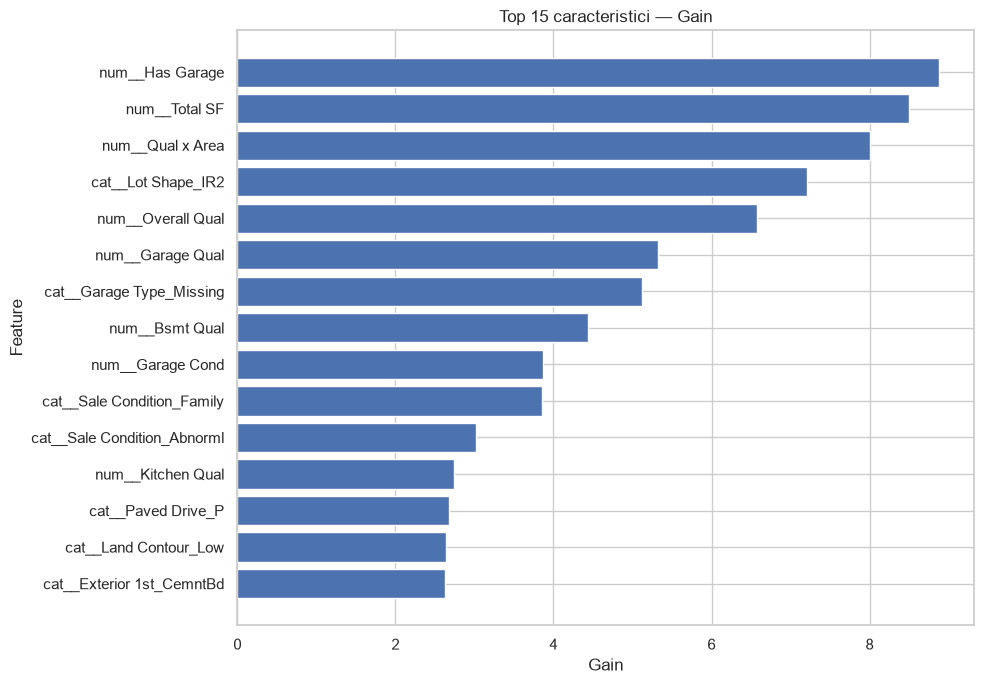

In [20]:
#Grafic pt Gain
top_gain = importance_df.head(15).sort_values("Gain")

plt.figure(figsize=(10, 7))
plt.barh(top_gain["Feature"].astype(str), top_gain["Gain"])
plt.xlabel("Gain")
plt.ylabel("Feature")
plt.title("Top 15 caracteristici — Gain")
plt.tight_layout()
plt.show()

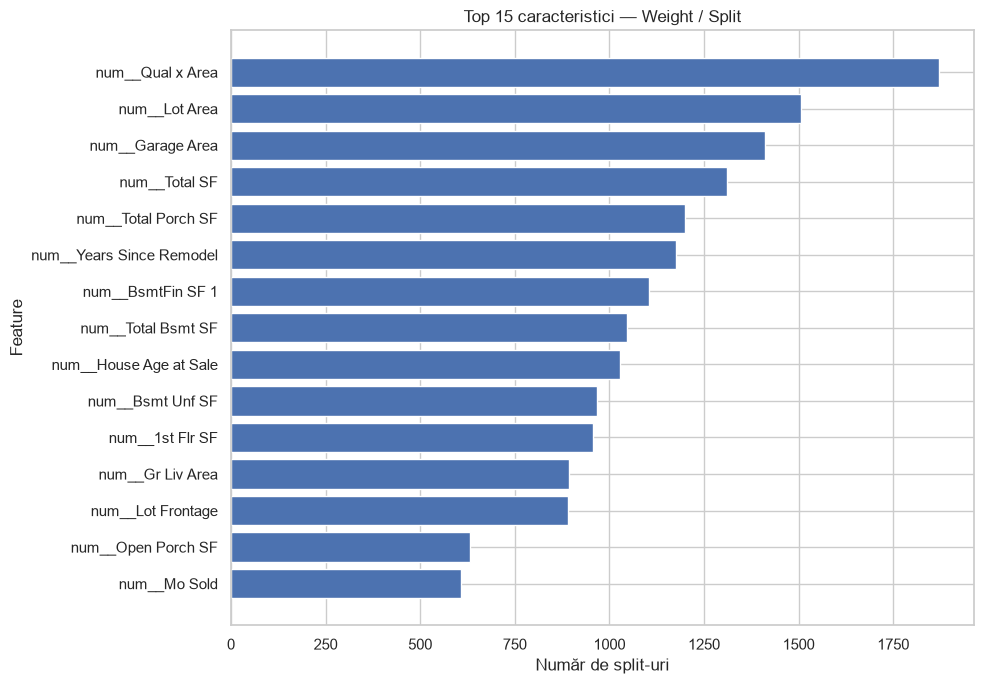

In [21]:
#Grafic pt Weight
top_weight = importance_df.sort_values(
    "Weight (Split)",
    ascending=False
).head(15).sort_values("Weight (Split)")

plt.figure(figsize=(10, 7))
plt.barh(
    top_weight["Feature"].astype(str),
    top_weight["Weight (Split)"]
)
plt.xlabel("Număr de split-uri")
plt.ylabel("Feature")
plt.title("Top 15 caracteristici — Weight / Split")
plt.tight_layout()
plt.show()

In [22]:
#Comparăm modelul de bază cu cel optimizat
comparison_results = pd.DataFrame([
    {
        "Model": "Baseline",
        "Test Accuracy": accuracy_score(
            y_test, baseline_predictions
        ),
        "Test Macro-F1": f1_score(
            y_test, baseline_predictions,
            average="macro",
            zero_division=0
        )
    },
    {
        "Model": "Optimized XGBoost",
        "Test Accuracy": accuracy_score(
            y_test, best_predictions
        ),
        "Test Macro-F1": f1_score(
            y_test, best_predictions,
            average="macro",
            zero_division=0
        )
    }
])

display(comparison_results.round(4))

,Model,Test Accuracy,Test Macro-F1
0,Baseline,0.7709,0.7417
1,Optimized XGBoost,0.7846,0.7942
